# 04 · Customer Sentiment Analysis
**Assessment task 6.** Only the **customer's** turns are analysed. The LLM returns:
- overall label (Negative / Neutral / Positive) + justification + evidence quotes + confidence,
- label at the **start** (first third of customer turns) and at the **end** (last third).

The trend (Improved / Worsened / Unchanged) is computed in code from the two labels, so it is always consistent.

In [1]:
# ---- Setup: open the project folder (run this cell first) ----
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")                       # results are saved to Drive, so they survive restarts
    PROJECT_DIR = "/content/drive/MyDrive/call-center-ai"  # <- change if your folder is elsewhere
else:
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
print("Working in:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/call-center-ai


In [ ]:
!pip install -q groq pandas matplotlib
import os; os.kill(os.getpid(), 9)  # restart session after install; then run Setup again and continue

In [2]:
from src import config
from src.llm import GroqLLM
from src.sentiment import SentimentAnalyzer
from src.pipeline import CallCenterPipeline, load_transcripts, done_ids

pipe = CallCenterPipeline(sentiment=SentimentAnalyzer(GroqLLM()))
done = done_ids(config.SENTIMENT_FILE)
for rec in load_transcripts():
    if rec["call_id"] in done:
        continue
    s = pipe.analyze_sentiment(rec)
    print(f"{rec['call_id']}: {s['overall_sentiment']:8s} ({s['start_sentiment']} → {s['end_sentiment']}) {s['justification']}")

Groq model: openai/gpt-oss-120b (fallbacks: ['openai/gpt-oss-20b', 'qwen/qwen3.8-27b'])
call_001: Negative (Negative → Positive) The customer begins the call frustrated about a delayed important package, showing clear dissatisfaction, but ends the conversation politely thanking the agent, indicating a more positive tone at the close.
call_002: Negative (Negative → Neutral) The customer begins the call expressing urgency and frustration about a delayed package containing important documents, indicating a negative tone. By the end, the customer is slightly more hopeful but still concerned about delays, resulting in a neutral tone overall.
call_003: Positive (Neutral → Positive) The customer begins with concerns and questions, showing a neutral tone, but ends the call expressing gratitude and appreciation, indicating a positive overall sentiment.
call_004: Positive (Negative → Positive) The customer begins the call distressed about being kicked out, showing frustration, but ends the conve

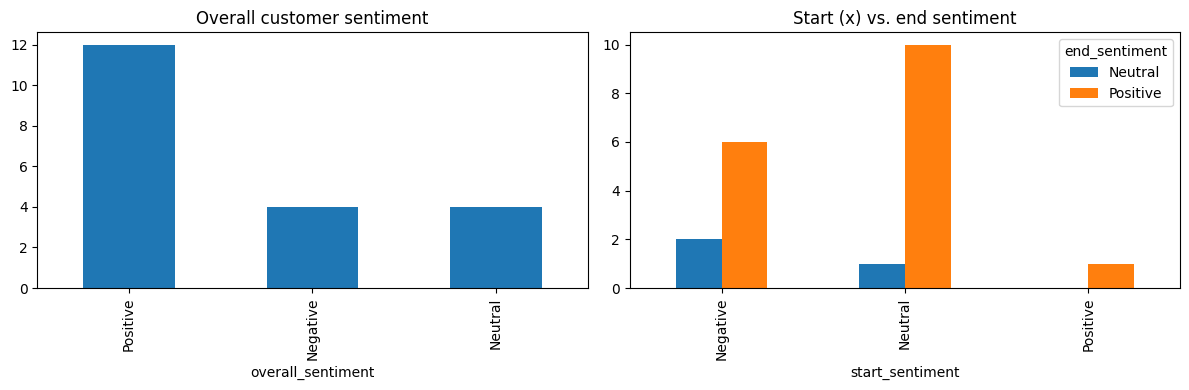

,call_id,overall_sentiment,start_sentiment,end_sentiment,trend,confidence,justification,evidence
0,call_001,Negative,Negative,Positive,Improved,0.92,The customer begins the call frustrated about ...,"[I'm waiting for a really important package, b..."
1,call_002,Negative,Negative,Neutral,Improved,0.92,The customer begins the call expressing urgenc...,"[""I really need these like yesterday... it has..."
2,call_003,Positive,Neutral,Positive,Improved,0.93,The customer begins with concerns and question...,[I'm just a bit worried whether my system can ...
3,call_004,Positive,Negative,Positive,Improved,0.86,The customer begins the call distressed about ...,[I've just been kicked out of my house because...
4,call_005,Positive,Negative,Positive,Improved,0.92,The customer begins the call worried about ove...,[It hasn't actually crashed out or anything bu...
5,call_006,Negative,Negative,Neutral,Improved,0.92,The customer begins the call frustrated about ...,"[""I recently bought a jacket... it's two sizes..."
6,call_007,Positive,Neutral,Positive,Improved,0.93,The customer begins with a neutral introductio...,"[okay brilliant um thank you very much, Brilli..."
7,call_008,Positive,Neutral,Positive,Improved,0.93,The customer begins by seeking information and...,[...I wasn't sure what's the real and what's t...
8,call_009,Positive,Neutral,Positive,Improved,0.93,The customer begins the call with a urgent but...,"[""Well the transfer is quite urgent..."", ""than..."
9,call_010,Positive,Positive,Positive,Unchanged,0.96,"The customer begins the call with clear, polit...","[Sounds good. Do any of them come furnished?, ..."


In [3]:
import pandas as pd, matplotlib.pyplot as plt
from src.utils import read_jsonl
sent = pd.DataFrame(read_jsonl(config.SENTIMENT_FILE)).drop_duplicates("call_id", keep="last")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sent["overall_sentiment"].value_counts().plot.bar(ax=ax[0], title="Overall customer sentiment")
pd.crosstab(sent["start_sentiment"], sent["end_sentiment"]).plot.bar(ax=ax[1], title="Start (x) vs. end sentiment")
plt.tight_layout(); plt.show()
sent[["call_id", "overall_sentiment", "start_sentiment", "end_sentiment", "trend", "confidence", "justification", "evidence"]]

## Uncertainty & errors (write your observations here)
- Low-confidence predictions: `sent[sent.confidence < 0.6]` — read these calls manually.
- Role-played calls may sound more polite/neutral than real customers → sentiment may be biased toward Neutral.
- Transcription errors in customer turns can change the label; compare with WER from notebook 02.

In [4]:
sent[sent['confidence'].astype(float) < 0.6]

,call_id,overall_sentiment,start_sentiment,end_sentiment,justification,evidence,confidence,trend


In [5]:
# Compare prompt v1 (no definitions) vs v2 (explicit definitions)
v1 = pd.DataFrame(read_jsonl(config.RESULTS_DIR / "sentiment_v1.jsonl")).drop_duplicates("call_id", keep="last").set_index("call_id")
v2 = sent.set_index("call_id")
cmp = pd.DataFrame({
    "v1": v1["start_sentiment"] + " → " + v1["end_sentiment"] + " = " + v1["overall_sentiment"],
    "v2": v2["start_sentiment"] + " → " + v2["end_sentiment"] + " = " + v2["overall_sentiment"],
})
print("Overall label changed in", (v1["overall_sentiment"] != v2["overall_sentiment"]).sum(), "of", len(v2), "calls")
print("v1 trends:", v1["trend"].value_counts().to_dict())
print("v2 trends:", v2["trend"].value_counts().to_dict())
cmp

Overall label changed in 3 of 20 calls
v1 trends: {'Improved': 19, 'Unchanged': 1}
v2 trends: {'Improved': 18, 'Unchanged': 2}


,v1,v2
call_id,,
call_001,Negative → Positive = Negative,Negative → Positive = Negative
call_002,Negative → Neutral = Negative,Negative → Neutral = Negative
call_003,Neutral → Positive = Positive,Neutral → Positive = Positive
call_004,Negative → Positive = Positive,Negative → Positive = Positive
call_005,Negative → Positive = Positive,Negative → Positive = Positive
call_006,Negative → Neutral = Negative,Negative → Neutral = Negative
call_007,Neutral → Positive = Positive,Neutral → Positive = Positive
call_008,Neutral → Positive = Positive,Neutral → Positive = Positive
call_009,Neutral → Positive = Positive,Neutral → Positive = Positive


## Sentiment validation & uncertainty

**Results (prompt v2, 20 calls):** overall Positive 12 · Negative 4 · Neutral 4. End-of-call: Positive 17 · Neutral 3 · Negative 0. Trend: Improved 18 · Unchanged 2.

**Prompt iteration:** prompt v1 had no definition of "overall", and calls with the same pattern (Negative → Positive) received three different overall labels. Prompt v2 defines overall as the *dominant* emotion across the call and treats routine politeness as Neutral. This changed the overall label in 4 of 20 calls (e.g., call_013 and call_019: Positive → Neutral). The justifications now explain the overall decision explicitly ("the frustration dominates").

**Remaining limitations:**
- **Politeness bias:** no call ends Negative; a closing "Thank you." is still sometimes labelled Positive (call_001), despite the instruction. Role-played calls also tend to end politely.
- **Prompt sensitivity:** changing only the instructions changed 20% of overall labels, so individual labels near a boundary are uncertain.
- **Self-reported confidence is not calibrated:** all values are 0.86–0.96 (one missing), so it cannot be used to find errors.
- The dataset has no sentiment labels → accuracy is measured with a manual review in notebook 05.